# M4. 고윳값·공분산·PCA: 데이터가 가장 넓게 퍼진 방향

**목표**
- 고유벡터를 "변환을 해도 방향이 안 바뀌고 늘거나 줄기만 하는 방향"으로 봅니다.
- 대칭행렬은 "돌리고 → 축마다 늘이고 → 되돌리기"로 쪼개진다는 것을 봅니다($A = Q\Lambda Q^\top$).
- 공분산 행렬의 칸 하나하나가 무엇인지 보고, **왜 그 고유벡터가 "데이터가 가장 넓게 퍼진 방향"인지** 직접 확인합니다.
- PCA 전에 표준화가 필요한 경우와, 배치 효과가 PC1 을 차지하는 예를 봅니다.

**이 노트북이 답하는 질문**: PCA 는 왜 하필 공분산 행렬의 고유벡터를 쓰나?

**같이 볼 강의**
- MIT 18.06 (Strang, 2010 봄) Lecture 21 "Eigenvalues and eigenvectors", Lecture 22 "Diagonalization and powers of A", Lecture 25 "Symmetric matrices and positive definiteness" [1]
- 3Blue1Brown "Essence of linear algebra" Chapter 13 "Change of basis", Chapter 14 "Eigenvectors and eigenvalues", Chapter 15 "A quick trick for computing eigenvalues" [2]

문장 끝의 `[번호]` 는 맨 아래 **출처** 절의 번호입니다. 그림 속 숫자는 따로 밝히지 않으면 **이 노트북의 장난감 예**입니다. 행렬 = 변환은 [M2](lab02_matrix-multiplication.ipynb), 투영은 [M1](lab01_vectors-dot.ipynb)을 보세요.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 색의 뜻은 행렬 노트북 M1~M5 공통
# e1·첫째 열 = 파랑, e2·둘째 열 = 빨강, 결과 = 초록, 변환 전 격자 = 옅은 회색, 변환 뒤 격자 = 진회색, 핵심 메시지 = 자주
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Polygon, Rectangle

COL = dict(e1="#0072B2", e2="#D55E00", result="#009E73", grid0="#D1D5DB", grid1="#374151",
           extra="#E69F00", sky="#56B4E9", highlight="#CC79A7", ink="#222222", muted="#6B7280",
           grid="#E5E7EB", shade="#FFF4E0", neutral="#F3F4F6")


def apply_theme():
    import logging
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}")


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """핵심 메시지: 자주색 굵은 글씨(흰 바탕)"""
    kw.setdefault("fontsize", 10); kw.setdefault("ha", "left"); kw.setdefault("va", "center")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, color=COL["highlight"], fontweight="semibold", **kw)


def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.014):
    """수식을 조각(chip)으로 그린다. parts = [(mathtext, color 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 그림의 같은 색과 짝을 이룬다.
    조각마다 '조각과 이름표 중 넓은 쪽' 만큼 자리를 잡아 이름표끼리 겹치지 않게 한다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lab, lw = None, 0.0
        if label:
            lab = ax.text(0, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                          color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)
            lw = lab.get_window_extent(renderer=r).transformed(inv).width
        items.append((t, bb, color, lab, max(bb.width, lw)))
    total = sum(w for *_, w in items) + gap * (len(items) - 1)
    x = (1 - total) / 2                                    # 가운데 정렬
    for t, bb, color, lab, w in items:
        x0 = x + (w - bb.width) / 2                         # 자리 가운데에 조각
        t.set_x(x0)
        if color:
            ax.add_patch(FancyBboxPatch((x0 - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if lab is not None:
            lab.set_x(x0 + bb.width / 2)
        x += w + gap


def show_formula(parts, title=None, height=1.35, width=10.5, fontsize=17):
    """수식 조각 그림 한 장(제목은 가운데)"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts, fontsize=fontsize)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11, fontweight="semibold",
                color=COL["ink"], transform=ax.transAxes)
    plt.show()


def arrow(ax, start, end, color, lw=2.2, label=None, label_off=(0.08, 0.08), zorder=4, ls="-", **kw):
    """두 점 사이 화살표(데이터 좌표) + 끝에 이름표"""
    a = FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, lw=lw, color=color,
                        zorder=zorder, linestyle=ls, shrinkA=0, shrinkB=0)
    ax.add_patch(a)
    if label:
        ax.text(end[0] + label_off[0], end[1] + label_off[1], label, color=color, fontsize=10.5,
                fontweight="semibold", zorder=zorder + 1, **kw)
    return a


def concept_map(boxes, edges, title="Concept map", size=(11, 3.6)):
    """개념 지도: boxes = {key: (x, y, text, color)}, edges = [(from, to), ...] (축 좌표 0~1)"""
    fig, ax = plt.subplots(figsize=size); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    for k, (x, y, text, color) in boxes.items():
        ax.text(x, y, text, ha="center", va="center", fontsize=9.5, color=COL["ink"], zorder=3,
                bbox=dict(boxstyle="round,pad=0.45", facecolor=color, edgecolor="none", alpha=0.9))
    for a, b in edges:
        (x0, y0, *_), (x1, y1, *_) = boxes[a], boxes[b]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.1,
                                    shrinkA=26, shrinkB=26, connectionstyle="arc3,rad=0.0"))
    ax.set_title(title)
    plt.show()


apply_theme()
BATCH_COL = [COL["sky"], COL["grid1"]]        # 배치 1, 2
GROUP_COL = [COL["extra"], COL["result"]]     # 생물학적 군 1, 2


def draw_concept_map_m4():
    boxes = {
        "T": (0.08, 0.55, "matrix =\ntransformation", COL["neutral"]),
        "eig": (0.26, 0.85, "eigenvector:\nonly stretched", "#DCEBF7"),
        "lam": (0.26, 0.25, "eigenvalue:\nhow much", "#DCEBF7"),
        "sym": (0.46, 0.55, "symmetric A =\nrotate·stretch·rotate", COL["neutral"]),
        "cov": (0.64, 0.85, "covariance matrix\n(symmetric)", "#D9F2E6"),
        "pca": (0.64, 0.25, "PCA = eigenvectors\nof covariance", "#D9F2E6"),
        "std": (0.86, 0.85, "standardise first\n(units)", COL["neutral"]),
        "batch": (0.86, 0.25, "PC1 can be\na batch effect", "#FDE7D2"),
    }
    edges = [("T", "eig"), ("T", "lam"), ("eig", "sym"), ("lam", "sym"), ("sym", "cov"), ("sym", "pca"),
             ("cov", "pca"), ("pca", "std"), ("pca", "batch")]
    concept_map(boxes, edges, title="M4 concept map: from 'directions a matrix only stretches' to PCA")


def draw_eigen_directions(A=((2, 1), (1, 2))):
    A = np.array(A, float); w, V = np.linalg.eigh(A)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.9), gridspec_kw={"width_ratios": [1, 1.1]})
    L = ax[0]
    th = np.radians(np.arange(0, 180, 22.5))
    for t in th:
        v = np.array([np.cos(t), np.sin(t)]); Av = A @ v
        eig = min(abs(np.cross(v, Av)), 9) < 1e-9
        L.plot([v[0], Av[0]], [v[1], Av[1]], color=COL["grid"], lw=0.7, zorder=1)
        arrow(L, (0, 0), v, COL["muted"], lw=1.0, zorder=2)
        arrow(L, (0, 0), Av, COL["result"] if eig and Av @ v > 2 else (COL["extra"] if eig else COL["grid1"]),
              lw=2.6 if eig else 1.2, zorder=3)
    circ = np.linspace(0, 2 * np.pi, 200)
    L.plot(np.cos(circ), np.sin(circ), color=COL["grid0"], lw=0.8)
    L.text(2.2, 2.55, "eigenvector (1, 1):\nstretched × 3", color=COL["result"], fontsize=10, fontweight="semibold")
    L.text(-1.65, 1.15, "eigenvector (−1, 1):\nstretched × 1", color=COL["extra"], fontsize=10, fontweight="semibold")
    L.set_xlim(-2.4, 3.6); L.set_ylim(-1.0, 3.3); L.set_aspect("equal"); L.set_axis_off()
    panel(L, "A", "grey: a unit vector v,  dark: A v")
    R = ax[1]
    tt = np.linspace(0, 180, 361); ang = []
    for t in np.radians(tt):
        v = np.array([np.cos(t), np.sin(t)]); Av = A @ v
        ang.append(np.degrees(np.arctan2(np.cross(v, Av), v @ Av)))
    R.plot(tt, ang, color=COL["ink"], lw=2)
    R.axhline(0, color=COL["muted"], lw=0.8)
    for t0, c, lab, xy in [(45, COL["result"], "45°: (1, 1)", (8, -14)), (135, COL["extra"], "135°: (−1, 1)", (142, -14))]:
        R.scatter([t0], [0], s=70, color=c, zorder=4)
        R.annotate(lab, xy=(t0, 0), xytext=xy, color=c, fontsize=9.5, fontweight="semibold",
                   arrowprops=dict(arrowstyle="-", color=c, lw=0.9))
    R.set_xlabel("direction of v (degrees)"); R.set_ylabel("turn from v to A v (degrees)")
    R.yaxis.grid(True); R.set_axisbelow(True)
    callout(R, 60, 24, "zero turn = eigenvector", fontsize=10)
    panel(R, "B", "How much A turns each direction")
    plt.tight_layout(); plt.show()
    return w, V


def draw_rotate_stretch(A=((2, 1), (1, 2))):
    A = np.array(A, float); w, Q = np.linalg.eigh(A); order = np.argsort(w)[::-1]; w = w[order]; Q = Q[:, order]
    if np.linalg.det(Q) < 0:
        Q[:, 1] *= -1
    t = np.linspace(0, 2 * np.pi, 300); circle = np.vstack([np.cos(t), np.sin(t)])
    marks = np.vstack([np.cos(np.radians([0, 90])), np.sin(np.radians([0, 90]))])
    stages = [("A", "Start: unit circle", np.eye(2)), ("B", "1. rotate by Qᵀ", Q.T),
              ("C", "2. stretch by Λ", np.diag(w) @ Q.T), ("D", "3. rotate back by Q = A", Q @ np.diag(w) @ Q.T)]
    fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.6))
    for a, (let, title, M) in zip(ax, stages):
        P = M @ circle
        a.fill(P[0], P[1], color=COL["result"], alpha=0.12, lw=0)
        a.plot(P[0], P[1], color=COL["result"], lw=1.8)
        if let in ("C", "D"):
            for k, c in enumerate([COL["result"], COL["extra"]]):
                ax_dir = w[k] * np.eye(2)[:, k] if let == "C" else w[k] * Q[:, k]   # C: 축 방향, D: 고유벡터 방향
                arrow(a, (0, 0), ax_dir, c, lw=2.4)
        m = M @ np.array([1.0, 0.0])
        a.scatter([m[0]], [m[1]], s=28, color=COL["ink"], zorder=5)
        a.set_xlim(-3.3, 3.3); a.set_ylim(-3.3, 3.3); a.set_aspect("equal"); a.set_axis_off()
        a.axhline(0, color=COL["grid"], lw=0.8, zorder=0); a.axvline(0, color=COL["grid"], lw=0.8, zorder=0)
        panel(a, let, title)
    callout(ax[3], -3.2, -3.0, f"long axis {w[0]:g} along (1, 1)\nshort axis {w[1]:g} along (−1, 1)", fontsize=9.5, va="bottom")
    plt.tight_layout(); plt.show()
    return w, Q


def draw_covariance(n=300, seed=3):
    rng = np.random.default_rng(seed)
    g1 = rng.normal(0, 1.0, n); g2 = 0.8 * g1 + rng.normal(0, 0.6, n)
    X = np.column_stack([g1, g2]); Xc = X - X.mean(0); C = Xc.T @ Xc / (n - 1)
    w, V = np.linalg.eigh(C); order = np.argsort(w)[::-1]; w = w[order]; V = V[:, order]
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
    L = ax[0]
    L.scatter(Xc[:, 0], Xc[:, 1], s=12, color=COL["grid1"], alpha=0.5, linewidths=0)
    t = np.linspace(0, 2 * np.pi, 200)
    ell = V @ np.diag(2 * np.sqrt(w)) @ np.vstack([np.cos(t), np.sin(t)])
    L.plot(ell[0], ell[1], color=COL["result"], lw=1.6)
    L.set_aspect("equal"); L.set_xlabel("gene 1 (centred)"); L.set_ylabel("gene 2 (centred)")
    L.set_xlim(-3.6, 3.6); L.set_ylim(-3.4, 3.4); L.yaxis.grid(True); L.set_axisbelow(True)
    note(L, -3.4, 3.0, "green ellipse = 2 standard deviations\nin every direction", fontsize=9)
    panel(L, "A", f"{n} samples, two correlated genes")
    R = ax[1]; R.set_axis_off(); R.set_xlim(0, 1); R.set_ylim(0, 1)
    cells = [[("var(gene 1)", C[0, 0], COL["e1"]), ("cov(1, 2)", C[0, 1], COL["grid1"])],
             [("cov(2, 1)", C[1, 0], COL["grid1"]), ("var(gene 2)", C[1, 1], COL["e2"])]]
    for i in range(2):
        for j in range(2):
            name, val, c = cells[i][j]
            x0, y0 = 0.12 + j * 0.42, 0.62 - i * 0.34
            R.add_patch(FancyBboxPatch((x0, y0), 0.38, 0.28, boxstyle="round,pad=0,rounding_size=0.03",
                                       facecolor=c, alpha=0.13, edgecolor="none"))
            R.text(x0 + 0.19, y0 + 0.18, f"{val:.2f}", ha="center", va="center", fontsize=16, fontweight="semibold", color=c)
            R.text(x0 + 0.19, y0 + 0.07, name, ha="center", va="center", fontsize=9.5, color=COL["muted"])
    callout(R, 0.12, 0.08, "diagonal = spread of each gene\noff-diagonal = do they move together?", fontsize=9.8, va="center")
    panel(R, "B", "The covariance matrix C")
    plt.tight_layout(); plt.show()
    return X, C, w, V


def draw_variance_by_direction(X, C, w, V):
    Xc = X - X.mean(0)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1, 1.15]})
    L = ax[0]
    L.scatter(Xc[:, 0], Xc[:, 1], s=12, color=COL["grid1"], alpha=0.45, linewidths=0)
    for k, (c, name) in enumerate([(COL["result"], "PC1"), (COL["extra"], "PC2")]):
        d = V[:, k] * 2 * np.sqrt(w[k]) * (1 if V[0, k] >= 0 else -1)
        arrow(L, (0, 0), d, c, lw=3, zorder=5)
        L.text(d[0] * 1.08, d[1] * 1.08 + (0.15 if k == 0 else 0), name, color=c, fontsize=11, fontweight="semibold")
    L.set_aspect("equal"); L.set_xlim(-3.6, 3.6); L.set_ylim(-3.4, 3.4)
    L.set_xlabel("gene 1 (centred)"); L.set_ylabel("gene 2 (centred)")
    panel(L, "A", "PC1 = direction of greatest spread")
    R = ax[1]
    th = np.linspace(0, 180, 361); var = []
    for t in np.radians(th):
        u = np.array([np.cos(t), np.sin(t)]); var.append(np.var(Xc @ u, ddof=1))
    var = np.array(var)
    R.plot(th, var, color=COL["ink"], lw=2)
    a1 = np.degrees(np.arctan2(V[1, 0], V[0, 0])) % 180; a2 = np.degrees(np.arctan2(V[1, 1], V[0, 1])) % 180
    R.scatter([a1], [w[0]], s=70, color=COL["result"], zorder=4); R.scatter([a2], [w[1]], s=70, color=COL["extra"], zorder=4)
    R.annotate(f"max = λ₁ = {w[0]:.2f} at PC1 ({a1:.0f}°)", xy=(a1, w[0]), xytext=(a1 + 32, w[0] - 0.05),
               color=COL["result"], fontsize=9.5, fontweight="semibold", va="center",
               arrowprops=dict(arrowstyle="-", color=COL["result"], lw=0.9))
    R.annotate(f"min = λ₂ = {w[1]:.2f} at PC2 ({a2:.0f}°)", xy=(a2, w[1]), xytext=(a2 - 70, w[1] + 0.05),
               color=COL["extra"], fontsize=9.5, fontweight="semibold", va="center", ha="right",
               arrowprops=dict(arrowstyle="-", color=COL["extra"], lw=0.9))
    R.set_xlabel("direction of the line we project onto (degrees)"); R.set_ylabel("variance of the shadows")
    R.yaxis.grid(True); R.set_axisbelow(True); R.set_xlim(0, 180)
    panel(R, "B", "Spread of the shadows, direction by direction")
    plt.tight_layout(); plt.show()
    return th, var


def draw_standardise(n=300, seed=8):
    rng = np.random.default_rng(seed)
    g1 = rng.normal(0, 1, n); g2 = 0.8 * g1 + rng.normal(0, 0.6, n); g3 = rng.normal(0, 1, n)
    X = np.column_stack([g1, g2, 100 * g3])                # 유전자 3 은 상관이 없고, 숫자만 100 배 큰 단위
    def pc1(M):
        Mc = M - M.mean(0); C = np.cov(Mc.T); w, V = np.linalg.eigh(C); v = V[:, np.argmax(w)]
        return v * np.sign(v[np.argmax(np.abs(v))])
    Z = (X - X.mean(0)) / X.std(0, ddof=1)
    v_raw, v_std = pc1(X), pc1(Z)
    fig, ax = plt.subplots(1, 3, figsize=(12.5, 4.0), gridspec_kw={"width_ratios": [1, 1, 0.9]})
    for a_, M, (i, j), v, title, let in [(ax[0], X - X.mean(0), (0, 2), v_raw, "Raw: gene 3 is in 100× units", "A"),
                                         (ax[1], Z, (0, 1), v_std, "Standardised: genes 1 and 2", "B")]:
        a_.scatter(M[:, i], M[:, j], s=10, color=COL["grid1"], alpha=0.45, linewidths=0)
        d = np.array([v[i], v[j]]); sc = np.abs(M[:, [i, j]]).max() * 0.85 / max(np.linalg.norm(d), 1e-9)
        a_.plot([-sc * d[0], sc * d[0]], [-sc * d[1], sc * d[1]], color=COL["result"], lw=2.5)
        a_.text(sc * d[0] * 0.6 + 0.04 * sc, sc * d[1] * 0.6, "PC1 (shadow)", color=COL["result"], fontsize=10.5, fontweight="semibold")
        a_.set_xlabel(f"gene {i + 1}"); a_.set_ylabel(f"gene {j + 1}")
        panel(a_, let, title)
    ax[0].set_xlim(-300, 300)
    c = ax[2]; y = np.arange(3)
    c.barh(y - 0.18, np.abs(v_raw), height=0.34, color=COL["grid1"], label="raw")
    c.barh(y + 0.18, np.abs(v_std), height=0.34, color=COL["result"], label="standardised")
    c.set_yticks(y, ["gene 1", "gene 2", "gene 3"]); c.invert_yaxis(); c.set_xlim(0, 1.15); c.set_xlabel("|PC1 loading|")
    c.legend(loc="lower right", fontsize=9)
    callout(c, 0.03, 0.68, "raw PC1 ≈ gene 3 (units)\nstandardised PC1 ≈ genes 1 + 2", fontsize=9.3)
    panel(c, "C", "Who drives PC1?")
    plt.tight_layout(); plt.show()
    return v_raw, v_std


def make_batch_data(n_per=15, genes=200, seed=21):
    rng = np.random.default_rng(seed)
    batch = np.repeat([0, 1], 2 * n_per); group = np.tile(np.repeat([0, 1], n_per), 2)
    X = rng.normal(0, 1, (4 * n_per, genes))
    X[:, :20] += 1.6 * group[:, None]                     # 생물학: 유전자 20 개가 군에 따라 다름
    X[:, 20:140] += 1.3 * batch[:, None]                  # 배치: 유전자 120 개가 배치에 따라 어긋남
    return X, batch, group


def draw_batch_pca(X, batch, group):
    Xc = X - X.mean(0); C = np.cov(Xc.T); w, V = np.linalg.eigh(C); order = np.argsort(w)[::-1]; w = w[order]; V = V[:, order]
    S = Xc @ V[:, :2]; ve = w / w.sum()
    fig, ax = plt.subplots(1, 3, figsize=(12.5, 4.1), gridspec_kw={"width_ratios": [1, 1, 0.8]})
    mk = ["o", "^"]
    for a_, colors, labels, key, let, title in [(ax[0], BATCH_COL, ["batch 1", "batch 2"], batch, "A", "Coloured by sequencing batch"),
                                               (ax[1], GROUP_COL, ["group 1", "group 2"], group, "B", "Coloured by biological group")]:
        for k in (0, 1):
            m = key == k
            a_.scatter(S[m, 0], S[m, 1], s=34, color=colors[k], marker=mk[k], linewidths=0, label=labels[k])
        a_.set_xlabel(f"PC1 ({ve[0]:.0%} of variance)"); a_.set_ylabel(f"PC2 ({ve[1]:.0%})")
        a_.legend(loc="upper center", fontsize=9, handletextpad=0.2)
        a_.yaxis.grid(True); a_.set_axisbelow(True)
        panel(a_, let, title)
    callout(ax[0], 0, 0, "PC1 splits\nthe batches", fontsize=10, ha="center")
    c = ax[2]; k = np.arange(1, 11)
    c.plot(k, ve[:10] * 100, color=COL["ink"], marker="o", lw=1.6)
    c.set_xlabel("component"); c.set_ylabel("variance explained (%)"); c.set_xticks(k)
    c.yaxis.grid(True); c.set_axisbelow(True)
    panel(c, "C", "Scree plot")
    plt.tight_layout(); plt.show()
    return S, ve

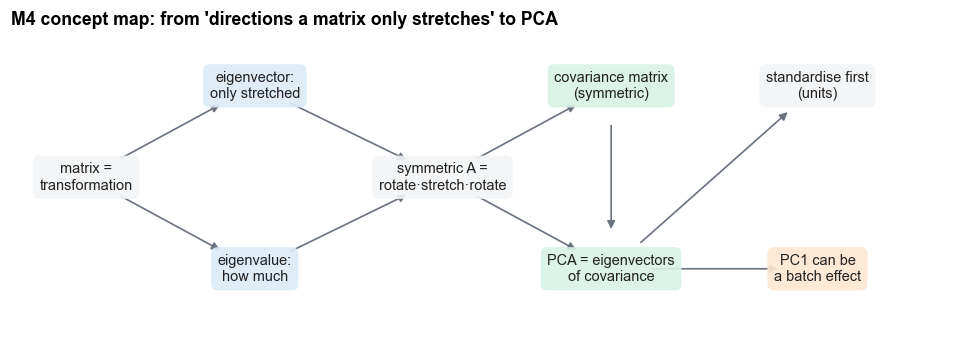

In [2]:
draw_concept_map_m4()

**그림에서 볼 것**
- 왼쪽: 변환에서 "방향은 그대로, 길이만 바뀌는" 특별한 방향이 고유벡터이고, 그 배율이 고윳값입니다.
- 가운데: 대칭행렬은 고유벡터끼리 직각이라 "돌리고·늘이고·되돌리기"로 쪼개집니다. 공분산 행렬이 대칭이라 PCA 가 여기서 나옵니다.
- 오른쪽: 실제로 PCA 를 쓸 때의 주의(단위, 배치 효과) 입니다.

## 1. 고유벡터: 변환해도 방향이 안 바뀌는 벡터

**한 줄 정의**: $Av = \lambda v$ 를 만족하는 **0 이 아닌** 벡터 v 가 고유벡터입니다. A 를 적용해도 v 는 **같은 직선 위**에 남고, 길이만 λ(고윳값) 배가 됩니다. (v = 0 은 어떤 λ 로도 식을 만족하므로 빼고 생각합니다.)

**왜 필요한가**: 대부분의 방향은 변환하면 돌아갑니다. 돌아가지 않는 방향을 찾으면 변환이 "그 축들을 따라 늘이기"로 단순해집니다. PCA 는 이 방향들을 데이터에서 찾는 일입니다.

**숫자로 따라가기**: A = [[2, 1], [1, 2]] 에 (1, 1) 을 넣으면 (3, 3) = 3 × (1, 1), (−1, 1) 을 넣으면 (−1, 1) = 1 × (−1, 1) 입니다. (1, 0) 을 넣으면 (2, 1) 로 방향이 바뀝니다.

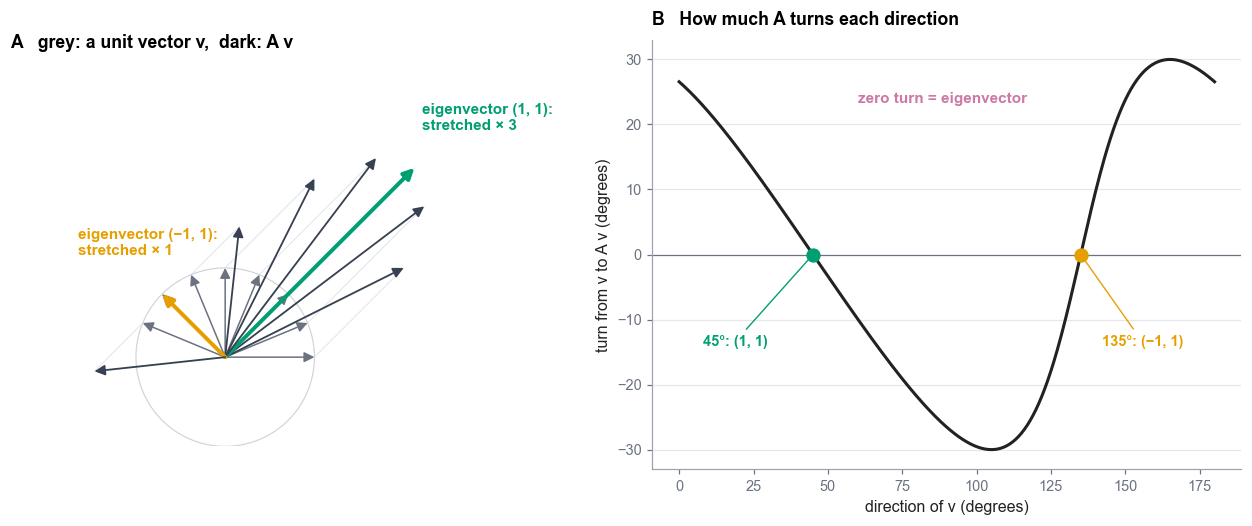

In [3]:
w_e, V_e = draw_eigen_directions()

**그림에서 볼 것**
- A: 회색 짧은 화살표가 단위 벡터 v, 진한 화살표가 Av 입니다. 대부분은 길이도 방향도 바뀝니다.
- 초록 화살표(45°, (1, 1))는 같은 방향으로 3 배, 주황 화살표(135°, (−1, 1))는 같은 방향 그대로 1 배입니다. 이 둘이 고유벡터입니다.
- B: 방향마다 "v 에서 Av 로 얼마나 돌았나"를 그렸습니다. 0° 를 지나는 두 점이 고유벡터입니다.

**수식 풀어 읽기**

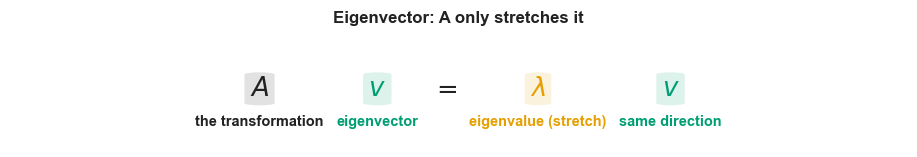

In [4]:
show_formula([(r"$A$", COL["ink"], "the transformation"), (r"$v$", COL["result"], "eigenvector"), (r"$=$", None, None),
              (r"$\lambda$", COL["extra"], "eigenvalue (stretch)"), (r"$v$", COL["result"], "same direction")],
             title="Eigenvector: A only stretches it")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $v$ | "v" | 방향이 안 바뀌는 벡터 | A 의 초록·주황 화살표 |
| $\lambda$ | "람다" | 늘어나는 배율(음수면 뒤집힘) | 초록 3, 주황 1 |

numpy 로 고윳값·고유벡터를 구해, 정의 $Av = \lambda v$ 를 그대로 확인합니다.

In [5]:
A = np.array([[2.0, 1.0], [1.0, 2.0]])
lam, V = np.linalg.eigh(A)
for k in range(2):
    assert np.allclose(A @ V[:, k], lam[k] * V[:, k])
assert np.allclose(sorted(lam), [1, 3])
assert np.allclose(A @ [1, 1], [3, 3]) and np.allclose(A @ [-1, 1], [-1, 1])
print("고윳값:", lam, " 고유벡터(열):\n", np.round(V, 3))

고윳값: [1. 3.]  고유벡터(열):
 [[-0.707  0.707]
 [ 0.707  0.707]]


## 2. 고윳값 구하기: det(A − λI) = 0

**한 줄 정의**: $Av = \lambda v$ 는 $(A - \lambda I)v = 0$ 과 같고, 0 이 아닌 v 가 있으려면 $A - \lambda I$ 가 평면을 더 낮은 차원으로(선, 또는 A = λI 이면 한 점으로) 눌러야(행렬식 0) 합니다.

**왜 필요한가**: M2 7절에서 "행렬식이 0 이면 여러 점이 한 점으로 겹친다"고 했습니다. 0 이 아닌 v 가 0 으로 보내지려면 바로 그런 행렬이어야 합니다.

**숫자로 따라가기**: A = [[2, 1], [1, 2]] 이면 det(A − λI) = (2 − λ)(2 − λ) − 1×1 = λ² − 4λ + 3 = (λ − 3)(λ − 1) 이라 λ = 3, 1 입니다.

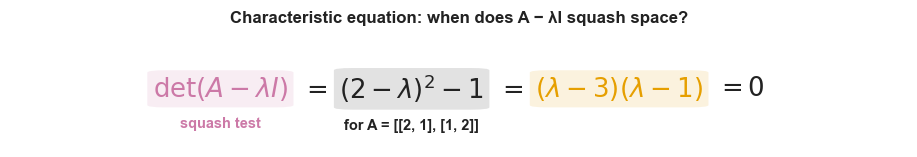

In [6]:
show_formula([(r"$\det(A - \lambda I)$", COL["highlight"], "squash test"), (r"$=$", None, None),
              (r"$(2-\lambda)^2 - 1$", COL["ink"], "for A = [[2, 1], [1, 2]]"), (r"$=$", None, None),
              (r"$(\lambda-3)(\lambda-1)$", COL["extra"], None), (r"$= 0$", None, None)],
             title="Characteristic equation: when does A − λI squash space?")

In [7]:
for l_ in (3.0, 1.0):
    assert np.isclose(np.linalg.det(A - l_ * np.eye(2)), 0)
assert not np.isclose(np.linalg.det(A - 2.0 * np.eye(2)), 0)
print("det(A − 3I) =", round(np.linalg.det(A - 3 * np.eye(2)), 6), "  det(A − 1I) =", round(np.linalg.det(A - np.eye(2)), 6))

det(A − 3I) = 0.0   det(A − 1I) = 0.0


**직접 바꿔 보기**: `draw_eigen_directions(A=((3, 0), (0, 1)))` 로 바꾸면 고유벡터는 어디일까요? 축 방향 그대로입니다.

In [8]:
# draw_eigen_directions(A=((3, 0), (0, 1)))

## 3. 대칭행렬: 돌리고, 늘이고, 되돌리기

**한 줄 정의**: 대칭행렬($A = A^\top$)은 고유벡터들이 서로 직각이고, $A = Q\Lambda Q^\top$ 로 쪼개집니다. Q 의 열은 고유벡터, Λ 는 고윳값을 대각선에 둔 행렬입니다(아래에서 숫자로 확인).

**왜 필요한가**: 이 분해는 "A 가 하는 일 = 고유벡터 축으로 돌려 놓고, 축마다 고윳값만큼 늘이고, 원래 자리로 돌리기"라는 뜻입니다. 공분산 행렬이 대칭이라 PCA 축이 서로 직각입니다.

**숫자로 따라가기**: A = [[2, 1], [1, 2]] 는 단위 원을 (1, 1) 방향으로 3, (−1, 1) 방향으로 1 만큼의 타원으로 바꿉니다.

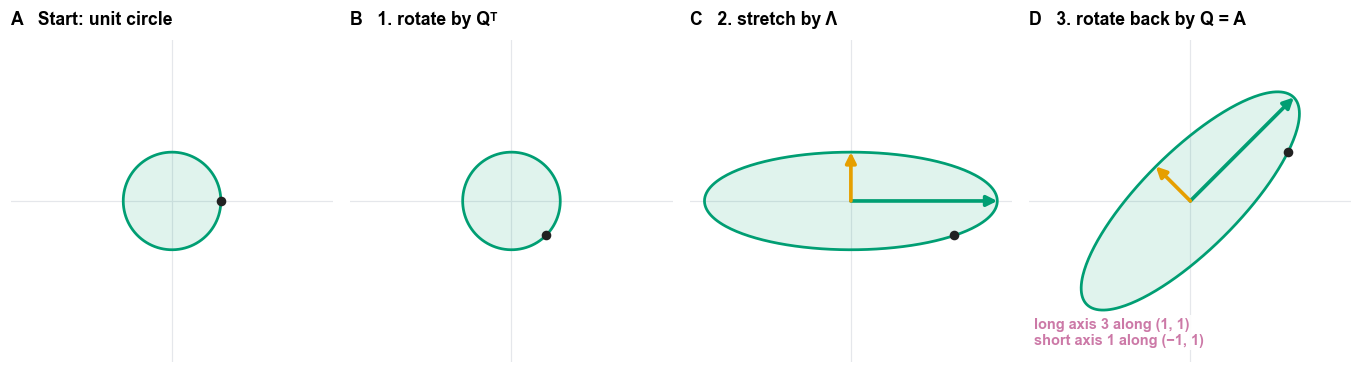

In [9]:
w_s, Q_s = draw_rotate_stretch()

**그림에서 볼 것**
- A → B: 원은 돌려도 원이지만, 검은 점(처음에 (1, 0) 이던 점)이 움직인 것으로 회전이 보입니다.
- C: 축 방향으로 3 배(초록), 1 배(주황) 늘여 타원이 됩니다.
- D: 다시 돌려 놓으면 긴 축이 (1, 1) 방향에 오고, 이것이 A 를 원에 적용한 결과와 같습니다.

**수식 풀어 읽기**

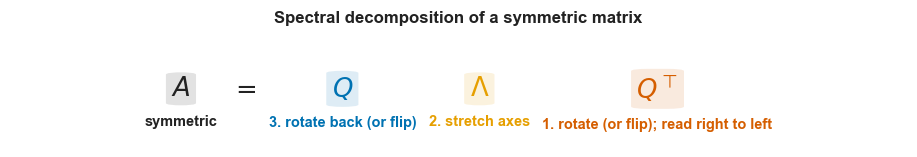

In [10]:
show_formula([(r"$A$", COL["ink"], "symmetric"), (r"$=$", None, None),
              (r"$Q$", COL["e1"], "3. rotate back (or flip)"), (r"$\Lambda$", COL["extra"], "2. stretch axes"),
              (r"$Q^\top$", COL["e2"], "1. rotate (or flip); read right to left")],
             title="Spectral decomposition of a symmetric matrix")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $Q$ | "큐" | 열 = 서로 직각인 단위 고유벡터, 회전(또는 뒤집기) | D 의 되돌리기 |
| $\Lambda$ | "대문자 람다" | 대각선 = 고윳값, 축마다 늘이기 | C |
| $Q^\top$ | "큐 전치" | Q 를 되돌리는 회전($Q^\top Q = I$) | B |

In [11]:
assert np.allclose(Q_s @ np.diag(w_s) @ Q_s.T, A) and np.allclose(Q_s.T @ Q_s, np.eye(2))
assert np.isclose(Q_s[:, 0] @ Q_s[:, 1], 0) and np.isclose(np.linalg.det(Q_s), 1)
Q_flip = Q_s.copy(); Q_flip[:, 1] *= -1                       # 고유벡터 부호를 바꿔도 분해는 그대로, Q 는 뒤집기가 됨
assert np.allclose(Q_flip @ np.diag(w_s) @ Q_flip.T, A) and np.isclose(np.linalg.det(Q_flip), -1)
print("det Q =", round(np.linalg.det(Q_s), 6), "(회전),  한 열의 부호를 바꾸면 det =", round(np.linalg.det(Q_flip), 6), "(뒤집기), 분해는 둘 다 성립")

det Q = 1.0 (회전),  한 열의 부호를 바꾸면 det = -1.0 (뒤집기), 분해는 둘 다 성립


고유벡터 v 와 −v 는 같은 직선이라 Q 의 열 부호는 마음대로 고를 수 있습니다. 이 노트북은 $\det Q = +1$ 이 되게 골라 Q 가 순수한 회전이 되게 했습니다. 부호를 다르게 고르면 Q 는 회전에 거울 뒤집기가 섞인 것이 되지만, $Q\Lambda Q^\top = A$ 는 그대로입니다(위 셀에서 확인).
print("Q Λ Qᵀ == A, QᵀQ == I, 고유벡터끼리 내적 =", round(Q_s[:, 0] @ Q_s[:, 1], 12))

## 4. 공분산 행렬: 퍼짐과 같이 움직임을 담은 표

**한 줄 정의**: 공분산 행렬 C 의 대각선 칸은 각 변수(유전자)의 분산, 나머지 칸은 두 변수가 함께 움직이는 정도(공분산)입니다. 평균을 뺀 데이터 $X_c$(표본 × 유전자)로 $C = X_c^\top X_c / (n-1)$ 입니다.

**왜 필요한가**: 데이터 구름의 모양(어느 쪽으로 길쭉한가)이 이 작은 대칭 표에 다 들어 있습니다. 그래서 이 표의 고유벡터가 구름의 축이 됩니다.

**숫자로 따라가기**: 표본 4 개, 유전자 2 개의 평균 뺀 값이 (−1, −1), (−1, 0), (1, 0), (1, 1) 이면

| 칸 | 계산 | 값 |
|---|---|---|
| var(유전자 1) | (1 + 1 + 1 + 1) / 3 | 1.33 |
| var(유전자 2) | (1 + 0 + 0 + 1) / 3 | 0.67 |
| cov(1, 2) | ((−1)(−1) + (−1)(0) + (1)(0) + (1)(1)) / 3 | 0.67 |

공분산이 양수이면 "한쪽이 클 때 다른 쪽도 큰 편"입니다.

In [12]:
Xc4 = np.array([[-1, -1], [-1, 0], [1, 0], [1, 1]], float)
C4 = Xc4.T @ Xc4 / 3
assert np.allclose(C4, [[4 / 3, 2 / 3], [2 / 3, 2 / 3]]) and np.allclose(C4, np.cov(Xc4.T))
print("C =", np.round(C4, 2).tolist())

C = [[1.33, 0.67], [0.67, 0.67]]


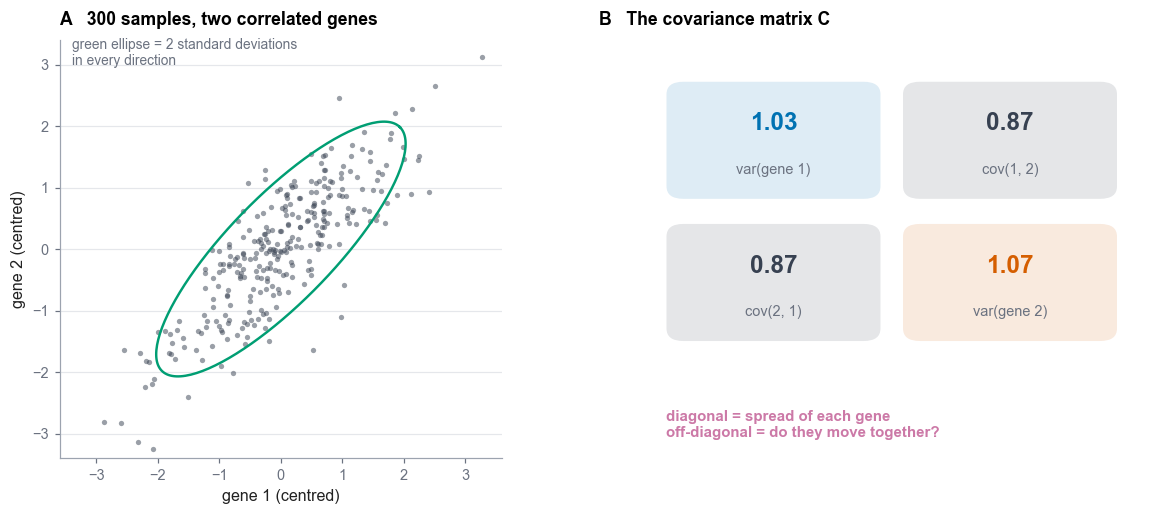

In [13]:
Xg, Cg, wg, Vg = draw_covariance()

**그림에서 볼 것**
- A: 유전자 두 개가 함께 오르내리는 표본 300 개입니다. 초록 타원이 구름의 모양(각 방향 2 표준편차)입니다.
- B: 공분산 행렬입니다. 파랑·빨강 칸이 각 유전자의 퍼짐, 회색 두 칸이 함께 움직이는 정도이고, 두 회색 칸은 같은 값(대칭)입니다.

**수식 풀어 읽기**

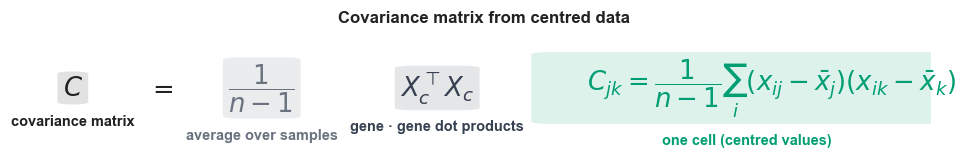

In [14]:
show_formula([(r"$C$", COL["ink"], "covariance matrix"), (r"$=$", None, None),
              (r"$\dfrac{1}{n-1}$", COL["muted"], "average over samples"),
              (r"$X_c^\top X_c$", COL["grid1"], "gene · gene dot products"),
              (r"$\qquad C_{jk} = \dfrac{1}{n-1}\sum_i (x_{ij}-\bar{x}_j)(x_{ik}-\bar{x}_k)$", COL["result"], "one cell (centred values)")],
             title="Covariance matrix from centred data")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $X_c$ | "엑스 씨" | 유전자마다 평균을 뺀 표(표본 × 유전자) | A 의 점들 |
| $C_{jk}$ | "C 의 j, k 칸" | 유전자 j 와 k 의 공분산(j = k 면 분산) | B 의 칸 |
| $\bar x_j$ | "엑스 바 j" | 유전자 j 의 평균. 빼고 곱해야 "평균보다 클 때 같이 큰가"를 잼 | - |
| $n - 1$ | "엔 빼기 일" | 표본 수 − 1 로 나눔(표본 분산의 관례) | - |

In [15]:
assert np.allclose(Cg, np.cov(Xg.T)) and np.allclose(Cg, Cg.T)
print("np.cov 와 같음, 대칭:", np.allclose(Cg, Cg.T))

np.cov 와 같음, 대칭: True


## 5. PCA: 왜 공분산의 고유벡터인가

**한 줄 정의**: PCA 는 서로 상관없는 새 변수(주성분)를 분산이 큰 순서로 만들고, 그것은 공분산 행렬의 고윳값·고유벡터 문제를 푸는 것과 같습니다 [3].

**왜 그런가** (이 노트북에서 확인)
1. 점들을 단위 방향 u 위로 투영하면(M1 의 그림자), 그림자들의 분산은 $u^\top C u$ 입니다.
2. u 를 한 바퀴 돌려 가며 이 값을 재면, **가장 큰 값은 C 의 가장 큰 고윳값 λ₁ 이고 그때의 u 가 그 고유벡터**입니다. 가장 작은 값은 λ₂ 이고 그 고유벡터는 첫째와 직각입니다.
3. 그래서 PC1 = 가장 넓게 퍼진 방향, PC2 = 그와 직각인 다음 방향이고, 각 PC 가 설명하는 분산 비율은 $\lambda_k / \sum \lambda$ 입니다.

**두 줄 증명** (이 노트북에서 유도)
- 그림자 분산: $\mathrm{var}(X_c u) = \dfrac{u^\top X_c^\top X_c\, u}{n-1} = u^\top C u$.
- 3절대로 $C = Q\Lambda Q^\top$ 이고, 길이 1 인 u 를 $u = Qc$ ($\lvert c\rvert = 1$, Q 가 회전이라 길이 유지)로 쓰면 $u^\top C u = c^\top \Lambda c = \sum_i \lambda_i c_i^2 \le \lambda_1 \sum_i c_i^2 = \lambda_1$ 입니다. 등호는 $c = e_1$, 즉 $u = $ 첫째 고유벡터일 때입니다.

**숫자로 따라가기**: 4절의 장난감 C = [[1.33, 0.67], [0.67, 0.67]] 의 고윳값은 1 ± √5/3, 즉 약 1.75 와 0.25 라 PC1 이 분산의 약 87% 를 설명합니다(대각합 2 = 1.75 + 0.25).

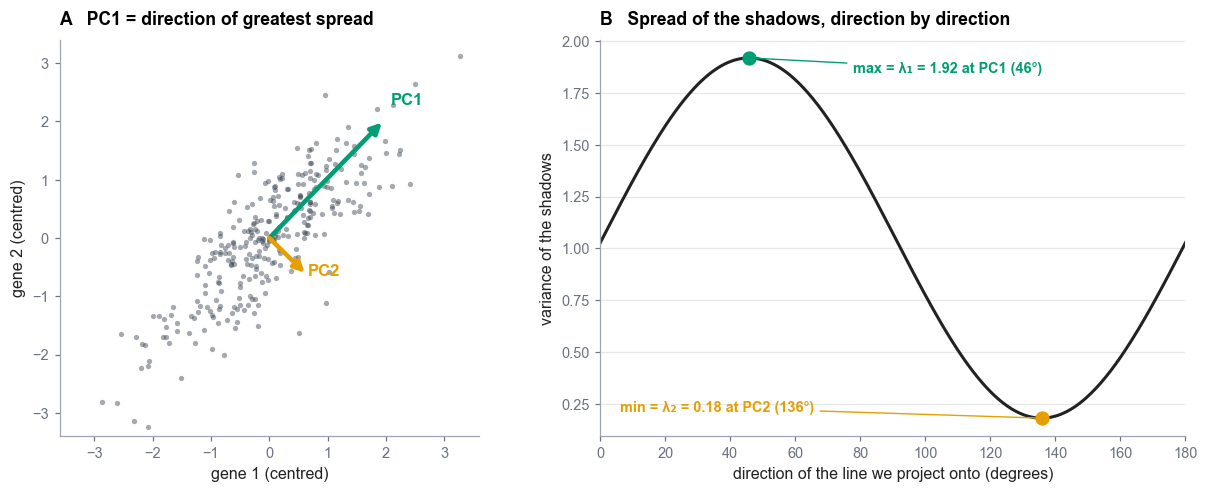

In [16]:
th, var = draw_variance_by_direction(Xg, Cg, wg, Vg)

**그림에서 볼 것**
- A: 초록 PC1 은 구름이 가장 길쭉한 방향, 주황 PC2 는 그와 직각입니다. 화살표 길이는 그 방향의 2 표준편차입니다.
- B: 방향을 0° 에서 180° 까지 돌려 가며 그림자의 분산을 쟀습니다. 곡선의 꼭대기가 정확히 PC1 방향과 λ₁, 바닥이 PC2 방향과 λ₂ 입니다.

**수식 풀어 읽기**

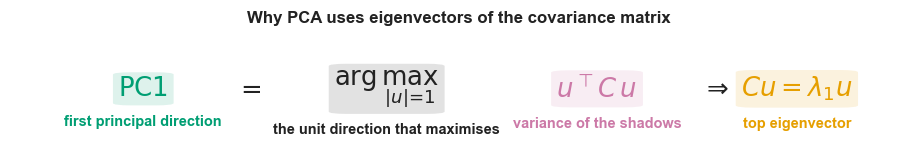

In [17]:
show_formula([(r"$\mathrm{PC1}$", COL["result"], "first principal direction"), (r"$=$", None, None),
              (r"$\arg\max_{|u|=1}$", COL["ink"], "the unit direction that maximises"),
              (r"$u^\top C\,u$", COL["highlight"], "variance of the shadows"), (r"$\;\Rightarrow\;$", None, None),
              (r"$C u = \lambda_1 u$", COL["extra"], "top eigenvector")],
             title="Why PCA uses eigenvectors of the covariance matrix")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $u^\top C u$ | "u 전치 C u" | 방향 u 위 그림자들의 분산 | B 의 곡선 높이 |
| $\arg\max_{\lvert u\rvert = 1}$ | "길이 1 인 u 중 가장 크게 만드는 것" | 최대가 되는 방향 자체 | B 의 꼭대기 |
| $\lambda_1$ | "람다 일" | 가장 큰 고윳값 = PC1 의 분산 | B 의 초록 점 높이 |

**기호 사전**: $\arg\max$ = "최대가 되는 값 자체(그때의 u)". 확인합니다: (1) 그림자 분산 = $u^\top C u$, (2) 곡선의 최댓값·최솟값 = 고윳값, (3) 장난감 C 의 설명 비율.

In [18]:
Xc_g = Xg - Xg.mean(0); u = np.array([np.cos(0.7), np.sin(0.7)])
assert np.isclose(np.var(Xc_g @ u, ddof=1), u @ Cg @ u)
assert np.isclose(var.max(), wg[0], rtol=1e-3) and np.isclose(var.min(), wg[1], rtol=1e-3)
lam4 = np.sort(np.linalg.eigvalsh(C4))[::-1]
assert np.allclose(lam4, [1 + np.sqrt(5) / 3, 1 - np.sqrt(5) / 3]) and np.isclose(lam4[0] / lam4.sum(), 0.8727, atol=1e-3)
print(f"그림자 분산 최대 {var.max():.3f} = λ₁ {wg[0]:.3f},  최소 {var.min():.3f} = λ₂ {wg[1]:.3f}")
print(f"장난감 C 의 고윳값 {np.round(lam4, 3)} → PC1 설명 비율 {lam4[0] / lam4.sum():.1%}")

그림자 분산 최대 1.918 = λ₁ 1.918,  최소 0.182 = λ₂ 0.182
장난감 C 의 고윳값 [1.745 0.255] → PC1 설명 비율 87.3%


> **시퀀싱 데이터에서는** 발현 행렬, copy number 행렬, 96칸 catalogue 행렬 모두에 PCA 를 씁니다. 다만 PCA 는 "무엇이 데이터를 가장 크게 흔드는가"를 보여 줄 뿐이라, 그것이 생물학인지 기술적 차이인지는 따로 확인해야 합니다(7절).

## 6. 표준화: 단위가 다르면 PCA 가 단위를 따라간다

**한 줄 정의**: 분산은 단위에 따라 달라지므로, 변수의 단위가 다르면 PCA 는 숫자가 큰 변수에 끌려갑니다. 그래서 흔히 각 변수를 평균 0, 표준편차 1 로 **표준화**한 뒤(= 상관 행렬로) PCA 를 합니다 [3].

**왜 필요한가**: 같은 유전자를 다른 척도(예: 한쪽만 100 배 큰 숫자)로 적으면 PC1 이 그 유전자 하나로 쏠립니다. 이것은 데이터의 구조가 아니라 단위의 결과입니다.

**숫자로 따라가기**: 유전자 세 개 중 1 과 2 는 서로 상관이 크고(r ≈ 0.8), 3 은 둘과 상관이 없는데 숫자만 100 배 큰 단위입니다. 원자료 PCA 는 단위 때문에 유전자 3 을, 표준화 PCA 는 상관 구조 때문에 유전자 1 + 2 를 PC1 으로 고릅니다.

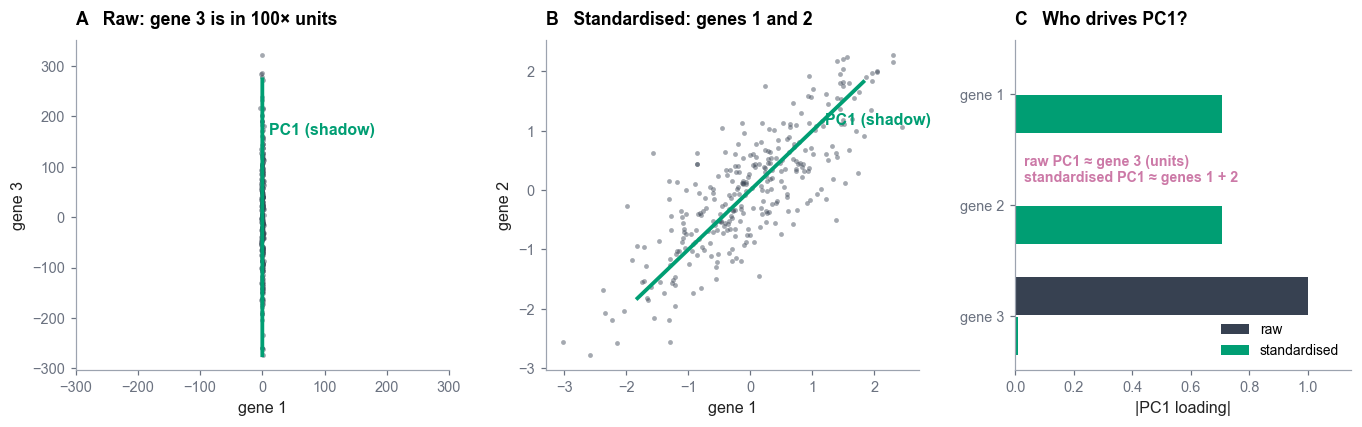

In [19]:
v_raw, v_std = draw_standardise()

**그림에서 볼 것**
- A: 유전자 3 의 숫자가 100 배라 원자료 PC1 의 그림자(초록)가 거의 세로(유전자 3) 입니다.
- B: 표준화하면 상관이 큰 유전자 1, 2 가 함께 PC1 을 이룹니다(초록이 두 축 사이 대각선).
- C: PC1 을 만드는 비중(loading)이 원자료에서는 거의 유전자 3 뿐이고, 표준화 뒤에는 유전자 1, 2 가 크고 유전자 3 은 거의 0 입니다.

주의: 변수가 **두 개뿐**이면 표준화 뒤의 상관 행렬은 늘 [[1, r], [r, 1]] 이라, PC1 은 r 의 크기와 상관없이 항상 대각선 (1, ±1)/√2 이고 바뀌는 것은 설명 비율 (1 + |r|)/2 뿐입니다. 그래서 위 예는 일부러 유전자를 세 개로 했습니다.

In [20]:
assert abs(v_raw[2]) > 0.99                                            # 원자료: 단위가 큰 유전자 3
assert abs(v_std[2]) < 0.2 and min(abs(v_std[0]), abs(v_std[1])) > 0.6   # 표준화: 상관된 1, 2
for r in (0.1, 0.5, 0.9):                                              # 변수 두 개면 PC1 은 r 과 무관하게 대각선
    w_, V_ = np.linalg.eigh(np.array([[1, r], [r, 1]]))
    assert np.allclose(np.abs(V_[:, -1]), 1 / np.sqrt(2)) and np.isclose(w_[-1] / 2, (1 + r) / 2)
print("원자료 PC1 비중:", np.round(np.abs(v_raw), 3), "  표준화 뒤:", np.round(np.abs(v_std), 3))

원자료 PC1 비중: [0. 0. 1.]   표준화 뒤: [0.707 0.707 0.01 ]


> **시퀀싱 데이터에서는** 로그 변환한 발현값처럼 모든 유전자가 **같은 단위**이면 표준화는 정답이 아니라 선택입니다. Jolliffe 와 Cadima 는 같은 단위로 잰 데이터에서는 공분산 행렬 PCA 가 맞고, 상관 행렬 PC 는 "변수마다 척도가 달라질 수 있는 데이터"에 맞는 선택이라고 씁니다 [3]. 또 z-점수로 표준화하면 분산이 작고 잡음이 많은 유전자도 큰 유전자와 같은 무게를 받는다는 점을 기억해 둡니다(이 노트북의 정리).

## 7. 응용: 배치 효과가 PC1 을 차지하는 경우

**한 줄 정의**: 시퀀싱 배치(기관, 장비, 시약 로트, 시기)처럼 생물학과 무관한 차이가 많은 유전자에 겹쳐 있으면, PC1 이 생물학이 아니라 **배치**를 가를 수 있습니다 [4].

**왜 필요한가**: Leek 등은 배치 효과가 실험실 조건, 시약 로트, 사람의 차이에서 생기고, 주성분은 생물학적 변동과 기술적 변동을 **둘 다** 담는다고 지적합니다 [4]. PCA 그림을 볼 때는 늘 배치로도 색칠해 봐야 합니다. Jolliffe 와 Cadima 도 PCA 의 주된 쓰임은 추론이 아니라 기술(descriptive)이라고 적습니다 [3].

**숫자로 따라가기**: 장난감 표본 60 개 × 유전자 200 개입니다. 생물학적 군이 유전자 20 개를, 배치가 유전자 120 개를 움직이도록 만들었습니다(배치와 군은 서로 섞여 있음).

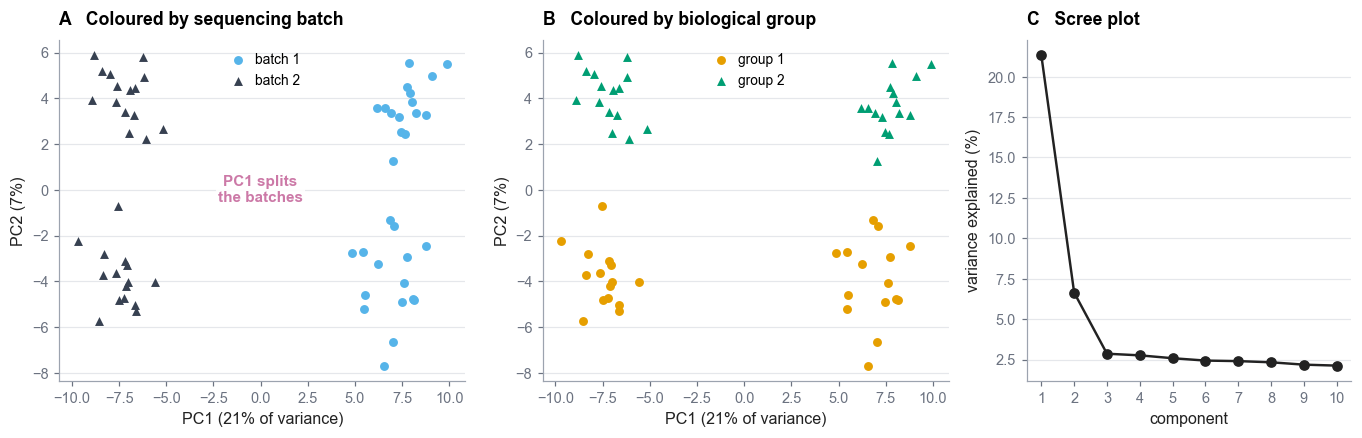

In [21]:
Xb, batch, group = make_batch_data()
S, ve = draw_batch_pca(Xb, batch, group)

**그림에서 볼 것**
- A: 같은 PCA 그림을 배치로 색칠하면 PC1 에서 두 배치(하늘색 원·진회색 세모)가 깨끗이 갈립니다.
- B: 생물학적 군(주황·초록)으로 색칠하면 PC1 에서는 섞여 있고, PC2 에서 갈립니다.
- C: 성분별 설명 비율입니다. 첫 성분(배치)이 가장 크고, 둘째(생물학)가 그다음입니다.

In [22]:
r_batch = abs(np.corrcoef(S[:, 0], batch)[0, 1]); r_group1 = abs(np.corrcoef(S[:, 0], group)[0, 1])
r_group2 = abs(np.corrcoef(S[:, 1], group)[0, 1])
assert r_batch > 0.9 and r_group1 < 0.3 and r_group2 > 0.8
print(f"|corr(PC1, 배치)| = {r_batch:.2f},  |corr(PC1, 군)| = {r_group1:.2f},  |corr(PC2, 군)| = {r_group2:.2f}")

|corr(PC1, 배치)| = 0.99,  |corr(PC1, 군)| = 0.04,  |corr(PC2, 군)| = 0.95


> **시퀀싱 데이터에서는** 여러 기관·시기에 걸쳐 모은 코호트에서 PC1 이 배치를 가르는 일이 흔합니다. 그래서 PCA 그림은 배치·기관·시퀀싱 장비로 각각 색칠해 보고, 생물학적 해석은 배치를 고려한 뒤에 합니다. 이 노트북의 숫자는 장난감 시뮬레이션이라 실제 코호트의 비율과는 무관합니다.

## 연습 문제

1. A = [[3, 0], [0, 1]] 의 고윳값과 고유벡터는?
2. A = [[4, 1], [2, 3]] 의 고윳값을 det(A − λI) = 0 으로 구하세요.
3. 공분산 행렬의 고윳값이 5, 3, 2 이면 PC1 이 설명하는 분산 비율은?
4. PCA 전에 표준화를 하지 않으면 무엇이 문제가 될 수 있나요?

<details><summary>정답 보기</summary>

1. 3 (방향 (1, 0)), 1 (방향 (0, 1)). 축 방향으로만 늘이는 변환입니다.
2. (4 − λ)(3 − λ) − 2 = λ² − 7λ + 10 = (λ − 5)(λ − 2) → 5, 2.
3. 5 / (5 + 3 + 2) = 50%.
4. 숫자 크기(단위)가 큰 변수가 PC1 을 독차지해, 구조가 아니라 단위를 보게 됩니다.

</details>

In [23]:
assert np.allclose(sorted(np.linalg.eigvals(np.array([[3, 0], [0, 1]]))), [1, 3])
assert np.allclose(sorted(np.linalg.eigvals(np.array([[4, 1], [2, 3]])).real), [2, 5])
assert np.isclose(5 / (5 + 3 + 2), 0.5)

## 정리

- 고유벡터는 변환해도 방향이 안 바뀌는 벡터, 고윳값은 그 배율입니다. det(A − λI) = 0 으로 구합니다.
- 대칭행렬은 $Q\Lambda Q^\top$ = 돌리기·늘이기·되돌리기로 쪼개지고, 고유벡터끼리 직각입니다.
- 공분산 행렬은 대칭이고, 방향 u 위 그림자의 분산이 $u^\top C u$ 라서 **가장 큰 분산의 방향 = 가장 큰 고윳값의 고유벡터** 입니다. 이것이 PCA 입니다.
- 단위가 다른 변수는 표준화(상관 행렬) 후 PCA 를 하고, PC 는 생물학과 배치를 함께 담을 수 있으니 배치로도 색칠해 봅니다.

## 출처

1. MIT OpenCourseWare, 18.06 Linear Algebra (Gilbert Strang), Spring 2010, Video Lectures 목록. https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/video_galleries/video-lectures/ — 머리의 "같이 볼 강의" 회차와 제목만 확인했습니다(Lecture 21·22·25). 본문의 정의·유도·숫자는 이 노트북에서 직접 한 것이고, 이 출처에 기대지 않습니다.
2. 3Blue1Brown (Grant Sanderson), "Essence of linear algebra" 재생목록. https://www.youtube.com/playlist?list=PLZHQObOWTQDPD3MizzM2xVFitgF8hE_ab — 머리의 "같이 볼 강의" 장 번호와 제목만 확인했습니다(Chapter 13·14·15).
3. Jolliffe IT, Cadima J (2016). Principal component analysis: a review and recent developments. *Philosophical Transactions of the Royal Society A* 374(2065):20150202. doi:10.1098/rsta.2015.0202, PMID 26953178, PMC4792409. — 초록 "creating new uncorrelated variables that successively maximize variance … reduces to solving an eigenvalue/eigenvector problem"(5절), 본문 "PCA can be based on either the covariance matrix or the correlation matrix", "PCs based on the covariance matrix S will change if the units of measurement on one or more of the variables change … it is common practice to begin by standardizing the variables"(6절), "In the fossil teeth data … all nine measurements are in the same units, so a covariance matrix PCA makes sense" 와 "Correlation matrix PCs are invariant to linear changes in units of measurement and are therefore the appropriate choice for datasets where different changes of scale are conceivable for each variable"(6절 시퀀싱 상자), "The main uses of PCA are descriptive, rather than inferential"(7절).
4. Leek JT, et al. (2010). Tackling the widespread and critical impact of batch effects in high-throughput data. *Nature Reviews Genetics* 11(10):733–739. doi:10.1038/nrg2825, PMID 20838408, PMC3880143. — 초록 "batch effects, which occur because measurements are affected by laboratory conditions, reagent lots and personnel differences", 본문 "Principal components capture both biological and technical variability" (7절).